# 实验报告02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

## 实验环境与提交要求

- 使用独立 conda 环境，安装 Python 3、NumPy、SciPy、Matplotlib、pandas
- 先把第一个代码框的学号改成自己的
- 图表要有标题、坐标轴标签、图例；随机抽样固定随机种子
- 提交前重启内核跑一遍全部代码，文件名为 学号_姓名

In [ ]:
import os
import sys
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244080234

# 使用sys.prefix获取当前conda环境
CONDA_ENV = os.path.basename(sys.prefix)
print(f"[Conda 环境] {CONDA_ENV}")

machine_finger = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

run_code = f"{STUDENT_ID}-{machine_finger}"
print(f"【学号】{STUDENT_ID}")
print(f"【设备指纹】{machine_finger}")
print(f"【运行编号】{run_code}")
print("numpy", np.__version__, "| scipy", scipy.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)


[Conda 环境] exp01_env
【学号】20244080234
【设备指纹】752642a01389f8fa
【运行编号】20244080234-752642a01389f8fa
numpy 2.2.5 | scipy 1.15.3 | pandas 2.3.3 | matplotlib 3.10.9


## 实验1：NumPy 数组、数据类型与索引

### 1.1 三种 dtype 的数组

In [2]:
a_int = np.array([1, 2, 3])
a_float = np.array([1.5, 2.5, 3.5])
a_bool = np.array([True, False, True])

for a in (a_int, a_float, a_bool):
    print(a, "dtype:", a.dtype, "shape:", a.shape, "ndim:", a.ndim)

[1 2 3] dtype: int64 shape: (3,) ndim: 1
[1.5 2.5 3.5] dtype: float64 shape: (3,) ndim: 1
[ True False  True] dtype: bool shape: (3,) ndim: 1


NumPy 数组里所有元素必须是同一种 `dtype`，内存连续存储，方便向量化计算；Python 列表可以混放不同类型，本质是对象引用的序列，更慢也更占内存。

### 1.2 reshape 改变形状

In [3]:
a = np.arange(12)
print("原数组:", a, a.shape)
b = a.reshape(3, 4)
print("(3,4):\n", b)
c = a.reshape(2, 3, 2)
print("(2,3,2):\n", c)

原数组: [ 0  1  2  3  4  5  6  7  8  9 10 11] (12,)
(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


改变形状前后元素总数必须相等（12 = 3×4 = 2×3×2），否则 `reshape` 会报错。

### 1.3 索引 (3,4) 数组

In [4]:
m = np.arange(12).reshape(3, 4)
print(m)
print("第2行:", m[1])
print("第1~3列:\n", m[:, 1:4])
big = m[m > 6]
print("大于6:", big, "形状:", big.shape)

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
第2行: [4 5 6 7]
第1~3列:
 [[ 1  2  3]
 [ 5  6  7]
 [ 9 10 11]]
大于6: [ 7  8  9 10 11] 形状: (5,)


### 1.4 布尔掩码，| 与 &

In [5]:
a = np.arange(10)
print("小于2或大于7:", a[(a < 2) | (a > 7)])
print("大于3且小于7:", a[(a > 3) & (a < 7)])
print("logical_or:", a[np.logical_or(a < 2, a > 7)])
print("logical_and:", a[np.logical_and(a > 3, a < 7)])

小于2或大于7: [0 1 8 9]
大于3且小于7: [4 5 6]
logical_or: [0 1 8 9]
logical_and: [4 5 6]


### 1.5 逐元素乘法 vs 矩阵乘法

In [6]:
x = np.array([[1, 2], [3, 4]])
y = np.array([[5, 6], [7, 8]])

print("x * y:\n", x * y)
print("np.multiply:\n", np.multiply(x, y))
print("x @ y:\n", x @ y)
print("np.matmul:\n", np.matmul(x, y))

x * y:
 [[ 5 12]
 [21 32]]
np.multiply:
 [[ 5 12]
 [21 32]]
x @ y:
 [[19 22]
 [43 50]]
np.matmul:
 [[19 22]
 [43 50]]


`*` 和 `np.multiply()` 是逐元素相乘（对应位置相乘）；`@` 和 `np.matmul()` 是真正的矩阵乘法，结果元素是行与列对应乘积之和。

## 实验2：随机抽样、统计与缺失值

### 2.1 模拟 1000 个成绩

In [7]:
rng = np.random.default_rng(42)
scores = rng.normal(70, 10, 1000)
scores = np.clip(scores, 0, 100)

print("样本数:", scores.size)
print("最小值:", scores.min())
print("最大值:", scores.max())
print("均值:", scores.mean())
print("标准差:", scores.std())
print("极差:", scores.max() - scores.min())

样本数: 1000
最小值: 33.51587174785217
最大值: 100.0
均值: 69.70929595324685
标准差: 9.881580939490172
极差: 66.48412825214783


### 2.2 不放回抽样：均匀 vs 按大小加权

In [8]:
rng = np.random.default_rng(1)
arr = np.arange(1, 11)
uniform = rng.choice(arr, size=5, replace=False)
w = arr / arr.sum()
weighted = rng.choice(arr, size=5, replace=False, p=w)

print("均匀抽样:", uniform)
print("按数值大小加权抽样:", weighted)

均匀抽样: [4 1 7 9 3]
按数值大小加权抽样: [ 7 10  8  2  9]


### 2.3 permutation vs shuffle

In [9]:
rng = np.random.default_rng(2)
a1 = np.arange(10)
perm = rng.permutation(a1)
print("permutation 前:", a1)
print("permutation 结果:", perm)
print("permutation 后原数组不变:", a1)

a2 = np.arange(10)
rng.shuffle(a2)
print("shuffle 后原数组(被原地改):", a2)

permutation 前: [0 1 2 3 4 5 6 7 8 9]
permutation 结果: [2 0 7 6 9 5 3 4 8 1]
permutation 后原数组不变: [0 1 2 3 4 5 6 7 8 9]
shuffle 后原数组(被原地改): [3 9 4 5 6 8 7 1 2 0]


`permutation` 返回新的打乱数组，不改原数组；`shuffle` 直接在原数组上乱序。

### 2.4 缺失值 nan

In [10]:
rng = np.random.default_rng(42)
valid = np.clip(rng.normal(70, 10, 1000), 0, 100).copy()
with_nan = valid.copy()
with_nan[10] = np.nan
with_nan[20] = np.nan
with_nan[30] = np.nan

print("普通均值(含nan):", with_nan.mean())
print("忽略nan的均值:", np.nanmean(with_nan))
print("缺失值个数:", np.isnan(with_nan).sum())

普通均值(含nan): nan
忽略nan的均值: 69.67997404325473
缺失值个数: 3


nan 会污染普通 `mean()`/`sum()` 这类统计函数的结果（变成 nan），需要用 `np.nanmean()`/`np.nansum()` 这类忽略缺失值的函数，或用 `np.isnan()` 掩码剔除。

### 2.5 整理成内存表格（供实验4用）

In [11]:
No = np.arange(1, len(with_nan) + 1)
score_table = pd.DataFrame({"No": No, "score": with_nan})
score_table.head()

,No,score
0,1,73.047171
1,2,59.600159
2,3,77.504512
3,4,79.405647
4,5,50.489648


## 实验3：SciPy 数值计算与 Matplotlib 可视化

### 3.1 解线性方程组

In [12]:
from scipy.linalg import solve

A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
sol = solve(A, b)
print("解:", sol)
print("代入验证 A@x =", A @ sol, "应等于", b)

解: [2. 3.]
代入验证 A@x = [9. 8.] 应等于 [9 8]


### 3.2 求方程 x² - 2 = 0 的根

In [13]:
from scipy.optimize import root

def f(x):
    return x[0] ** 2 - 2

r_pos = root(f, [1.0])    # 正根，初值取正数
r_neg = root(f, [-1.0])   # 负根，初值取负数
print("正根:", r_pos.x, "成功:", r_pos.success, "f(x):", f(r_pos.x))
print("负根:", r_neg.x, "成功:", r_neg.success, "f(x):", f(r_neg.x))

正根: [1.41421356] 成功: True f(x): -8.881784197001252e-16
负根: [-1.41421356] 成功: True f(x): -8.881784197001252e-16


### 3.3 求 f(x) = x² + x + 2 的最小值

In [14]:
from scipy.optimize import minimize

def g(x):
    return x[0] ** 2 + x[0] + 2

res = minimize(g, [0.0])
print("极小点:", res.x, "函数值:", res.fun)
# 解析解：导数为 2x+1=0，x=-0.5，f(-0.5)=1.75

极小点: [-0.50000001] 函数值: 1.75


### 3.4 独立样本 t 检验

In [15]:
from scipy import stats

rng = np.random.default_rng(7)
g1 = rng.normal(0, 1, 100)
g2 = rng.normal(1, 1, 100)

t_stat, p_val = stats.ttest_ind(g1, g2)
print("t 统计量:", t_stat)
print("p 值:", p_val)
print("p < 0.05 则拒绝原假设 ->", "两组均值有显著差异" if p_val < 0.05 else "无显著差异")

t 统计量: -8.735999955800951
p 值: 1.0189084750523264e-15
p < 0.05 则拒绝原假设 -> 两组均值有显著差异


### 3.5 Matplotlib 可视化

直方图 + 箱线图（用实验2的有效成绩），以及 y=x、y=x²、y=x³ 的折线图。

C:\Users\huan\AppData\Local\Temp\ipykernel_42112\390203228.py:14: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\huan\AppData\Local\Temp\ipykernel_42112\390203228.py:14: UserWarning: Glyph 32489 (\N{CJK UNIFIED IDEOGRAPH-7EE9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\huan\AppData\Local\Temp\ipykernel_42112\390203228.py:14: UserWarning: Glyph 39057 (\N{CJK UNIFIED IDEOGRAPH-9891}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\huan\AppData\Local\Temp\ipykernel_42112\390203228.py:14: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\huan\AppData\Local\Temp\ipykernel_42112\390203228.py:14: UserWarning: Glyph 30452 (\N{CJK UNIFIED IDEOGRAPH-76F4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\huan\AppData\Local\Temp\ipykernel_42112\390203228.py:14: UserWarning: Glyph 26041 (\N{CJK UNIFIE

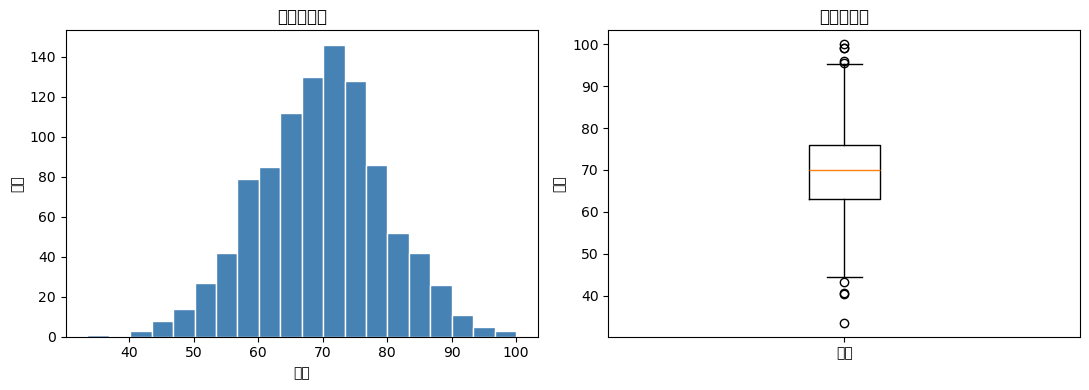

In [16]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(valid, bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("成绩直方图")
axes[0].set_xlabel("成绩")
axes[0].set_ylabel("频数")

axes[1].boxplot(valid)
axes[1].set_title("成绩箱线图")
axes[1].set_ylabel("成绩")
axes[1].set_xticklabels(["成绩"])
plt.tight_layout()
plt.show()

d:\anaconda\envs\exp01_env\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 19977 (\N{CJK UNIFIED IDEOGRAPH-4E09}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\anaconda\envs\exp01_env\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 31181 (\N{CJK UNIFIED IDEOGRAPH-79CD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\anaconda\envs\exp01_env\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20989 (\N{CJK UNIFIED IDEOGRAPH-51FD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\anaconda\envs\exp01_env\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


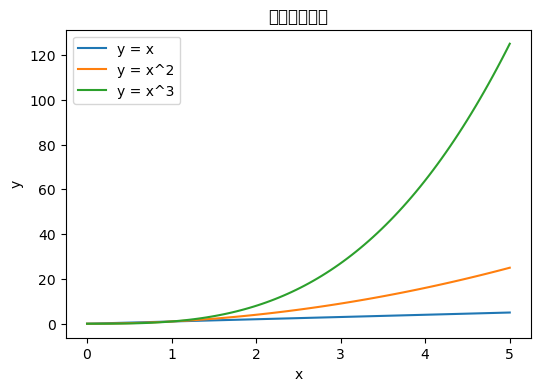

In [17]:
x = np.linspace(0, 5, 100)
plt.figure(figsize=(6, 4))
plt.plot(x, x, label="y = x")
plt.plot(x, x ** 2, label="y = x^2")
plt.plot(x, x ** 3, label="y = x^3")
plt.title("三种函数曲线")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

### 4.1 创建 DataFrame，加 Total 和 Average

In [18]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print(df)
print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print("前3行:\n", df.head(3))
print("基本统计:\n", df.describe())

      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
David     B    65       73      70    208  69.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000
行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
前3行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
基本统计:
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.

### 4.2 loc / iloc 与条件筛选

In [19]:
print("Carol (loc):\n", df.loc["Carol"])
print("Carol (iloc 第3行):\n", df.iloc[2])
print("平均分不低于80:\n", df[df["Average"] >= 80])

Carol (loc):
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
Carol (iloc 第3行):
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
平均分不低于80:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


### 4.3 axis=0 列均值 vs axis=1 行均值

In [20]:
print("三科列均值 (axis=0):\n", df[["Math", "English", "Python"]].mean(axis=0))
print("每名学生行均值 (axis=1):\n", df[["Math", "English", "Python"]].mean(axis=1))

三科列均值 (axis=0):
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64
每名学生行均值 (axis=1):
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


### 4.4 apply / agg / rank

In [21]:
df["Best"] = df[["Math", "English", "Python"]].apply(lambda r: max(r), axis=1)
print("每名学生三科最高分:\n", df[["Best"]])

print("每科 min/mean/max:\n", df[["Math", "English", "Python"]].agg(["min", "mean", "max"]))

df["TotalRank"] = df["Total"].rank(ascending=False)
print("按总分排名:\n", df[["Total", "TotalRank"]])

每名学生三科最高分:
        Best
Name       
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
每科 min/mean/max:
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000
按总分排名:
        Total  TotalRank
Name                   
Alice    273        1.0
Bob      220        5.0
Carol    265        2.0
David    208        6.0
Eva      257        3.0
Frank    243        4.0


### 4.5 按 Group 分组

In [22]:
grouped = df.groupby("Group")
print("每组人数:\n", grouped.size())
print("每组三科平均分:\n", grouped[["Math", "English", "Python"]].mean())

df["GroupPyMean"] = df.groupby("Group")["Python"].transform("mean")
print("所在组的Python平均分:\n", df[["Group", "Python", "GroupPyMean"]])

每组人数:
 Group
A    3
B    3
dtype: int64
每组三科平均分:
             Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333
所在组的Python平均分:
       Group  Python  GroupPyMean
Name                            
Alice     A      95    87.000000
Bob       A      80    87.000000
Carol     B      89    80.333333
David     B      70    80.333333
Eva       A      86    87.000000
Frank     B      82    80.333333


### 4.6 用 filter 保留 Python 平均分不低于 80 的组

In [23]:
group_mean = df.groupby("Group")["Python"].mean()
print("每组Python平均分:\n", group_mean)
high_groups = group_mean[group_mean >= 80].index
print("保留的组:", list(high_groups))
print(df[df["Group"].isin(high_groups)])

每组Python平均分:
 Group
A    87.000000
B    80.333333
Name: Python, dtype: float64
保留的组: ['A', 'B']
      Group  Math  English  Python  Total    Average  Best  TotalRank  \
Name                                                                    
Alice     A    88       90      95    273  91.000000    95        1.0   
Bob       A    72       68      80    220  73.333333    80        5.0   
Carol     B    91       85      89    265  88.333333    91        2.0   
David     B    65       73      70    208  69.333333    73        6.0   
Eva       A    79       92      86    257  85.666667    92        3.0   
Frank     B    84       77      82    243  81.000000    84        4.0   

       GroupPyMean  
Name                
Alice    87.000000  
Bob      87.000000  
Carol    80.333333  
David    80.333333  
Eva      87.000000  
Frank    80.333333  


### 4.7 协方差与相关系数

In [24]:
print("协方差矩阵:\n", df[["Math", "English", "Python"]].cov())
print("相关系数矩阵:\n", df[["Math", "English", "Python"]].corr())

协方差矩阵:
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667
相关系数矩阵:
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


看 Math 和 Python 这一对：协方差为正，说明两科成绩大致同向变化（某科高时另一科也倾向高）；相关系数范围在 -1~1 之间，绝对值越接近 1 说明线性关系越强，符号表示方向。